In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv("data\Diabetes_type.csv")
df.head()

,No. of Pregnancy,Age,BMI,BP(Systolic),BP(Diastolic),DiabetesPedigreeFunction,Insulin,Skin Thickness(mm),Type-2 Diabetic,Glucose
0,3,50,22.263762,140,90.0,0,0,317.50,1,146.0
1,1,40,24.111159,110,80.0,2,0,317.50,0,61.0
2,0,21,17.183204,120,80.0,0,0,259.08,1,97.0
3,2,30,21.244332,130,85.0,0,0,322.58,1,178.0
4,2,35,22.819490,110,75.0,0,0,335.28,1,167.0


In [2]:
def useful_info(df, name="DataFrame"):
    """Print a well-formatted overview of a DataFrame."""
    
    width = 60
    
    print("=" * width)
    print(f"{name.upper()} OVERVIEW".center(width))
    print("=" * width)
    
    print(f"\nShape: {df.shape[0]} rows × {df.shape[1]} columns\n")
    
    print("-" * width)
    print("INFO")
    print("-" * width)
    df.info()
    
    print("\n" + "-" * width)
    print("DTYPES")
    print("-" * width)
    print(df.dtypes.to_string())
    
    print("\n" + "-" * width)
    print("MISSING VALUES")
    print("-" * width)
    missing = df.isnull().sum()
    missing_pct = (missing / len(df) * 100).round(2)
    missing_df = pd.DataFrame({"missing": missing, "pct": missing_pct})
    missing_df = missing_df[missing_df["missing"] > 0]
    if missing_df.empty:
        print("No missing values ✅")
    else:
        print(missing_df.to_string())
    
    print("\n" + "-" * width)
    print("DESCRIBE (numeric)")
    print("-" * width)
    numeric_cols = df.select_dtypes(include="number").columns
    if len(numeric_cols) == 0:
        print("No numeric columns")
    else:
        print(df[numeric_cols].describe().T.to_string())
    
    print("\n" + "-" * width)
    print("DESCRIBE (categorical)")
    print("-" * width)
    cat_cols = df.select_dtypes(include=["object", "category"]).columns
    if len(cat_cols) == 0:
        print("No categorical columns")
    else:
        print(df[cat_cols].describe().T.to_string())
    
    print("\n" + "-" * width)
    print("DUPLICATES")
    print("-" * width)
    print(f"Duplicate rows: {df.duplicated().sum()}")
    
    print("=" * width + "\n")


useful_info(df)

                     DATAFRAME OVERVIEW                     

Shape: 1065 rows × 10 columns

------------------------------------------------------------
INFO
------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1065 entries, 0 to 1064
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   No. of Pregnancy          1065 non-null   int64  
 1   Age                       1065 non-null   int64  
 2   BMI                       1065 non-null   float64
 3   BP(Systolic)              1065 non-null   int64  
 4   BP(Diastolic)             1061 non-null   float64
 5   DiabetesPedigreeFunction  1065 non-null   int64  
 6   Insulin                   1065 non-null   int64  
 7   Skin Thickness(mm)        1058 non-null   float64
 8   Type-2 Diabetic           1065 non-null   int64  
 9   Glucose                   1065 non-null   float64
dtypes: float

In [3]:
# The empty column will be dealt with when building the pipeline
# next step is check for unique values
unique_counts = []
for col in df.columns:
    uniq = df[col].nunique()
    unique_counts.append({"columns": col, "no_unique": uniq})

print(pd.DataFrame(unique_counts))



                    columns  no_unique
0          No. of Pregnancy         13
1                       Age         55
2                       BMI        185
3              BP(Systolic)         15
4             BP(Diastolic)         14
5  DiabetesPedigreeFunction          8
6                   Insulin         21
7        Skin Thickness(mm)         40
8           Type-2 Diabetic          2
9                   Glucose        146


In [4]:
# this is a classification problem. the target column is type-2 Diabetes
TARGET = "Type-2 Diabetic"


In [5]:
# ratget distribution
print(df[TARGET].value_counts())
print("\n Normalized")
print(df[TARGET].value_counts(normalize = True).round(3))

Type-2 Diabetic
1    840
0    225
Name: count, dtype: int64

 Normalized
Type-2 Diabetic
1    0.789
0    0.211
Name: proportion, dtype: float64


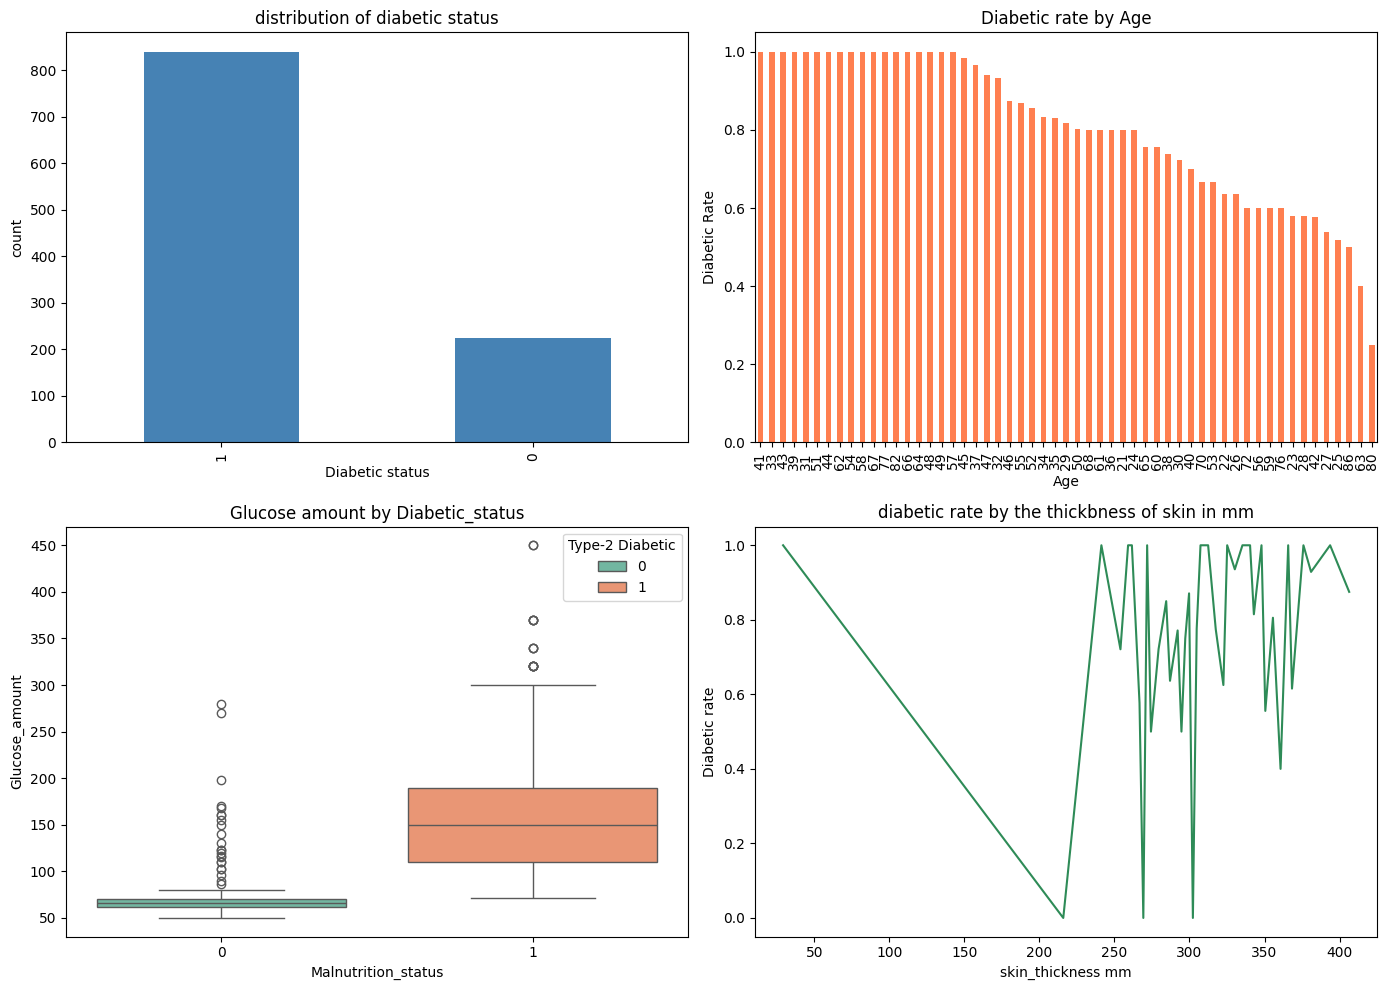

In [6]:
import seaborn as sns
# visualizations
fig, axes = plt.subplots(2, 2, figsize = (14, 10))
df[TARGET].value_counts().plot(kind = "bar", ax = axes[0, 0], color = 'steelblue')
axes[0, 0].set_title("distribution of diabetic status")
axes[0, 0].set_xlabel("Diabetic status")
axes[0, 0].set_ylabel("count")

df.groupby("Age")[TARGET].mean().sort_values(ascending = False).plot(kind = 'bar', ax = axes[0, 1], color = 'coral')
axes[0, 1].set_title("Diabetic rate by Age")
axes[0, 1].set_xlabel("Age")
axes[0, 1].set_ylabel("Diabetic Rate")
axes[0, 1].tick_params(axis = 'x', rotation = 90)

sns.boxplot(x = TARGET, y = 'Glucose', data = df, ax = axes[1, 0], palette = 'Set2', hue = TARGET)
axes[1, 0].set_title('Glucose amount by Diabetic_status')
axes[1, 0].set_xlabel('Malnutrition_status')
axes[1, 0].set_ylabel("Glucose_amount")

df.groupby('Skin Thickness(mm)')[TARGET].mean().plot(kind = 'line', ax = axes[1, 1], color ='seagreen' )
axes[1, 1].set_title('diabetic rate by the thickbness of skin in mm')
axes[1, 1].set_xlabel('skin_thickness mm')
axes[1, 1].set_ylabel('Diabetic rate')

plt.tight_layout()
plt.show()

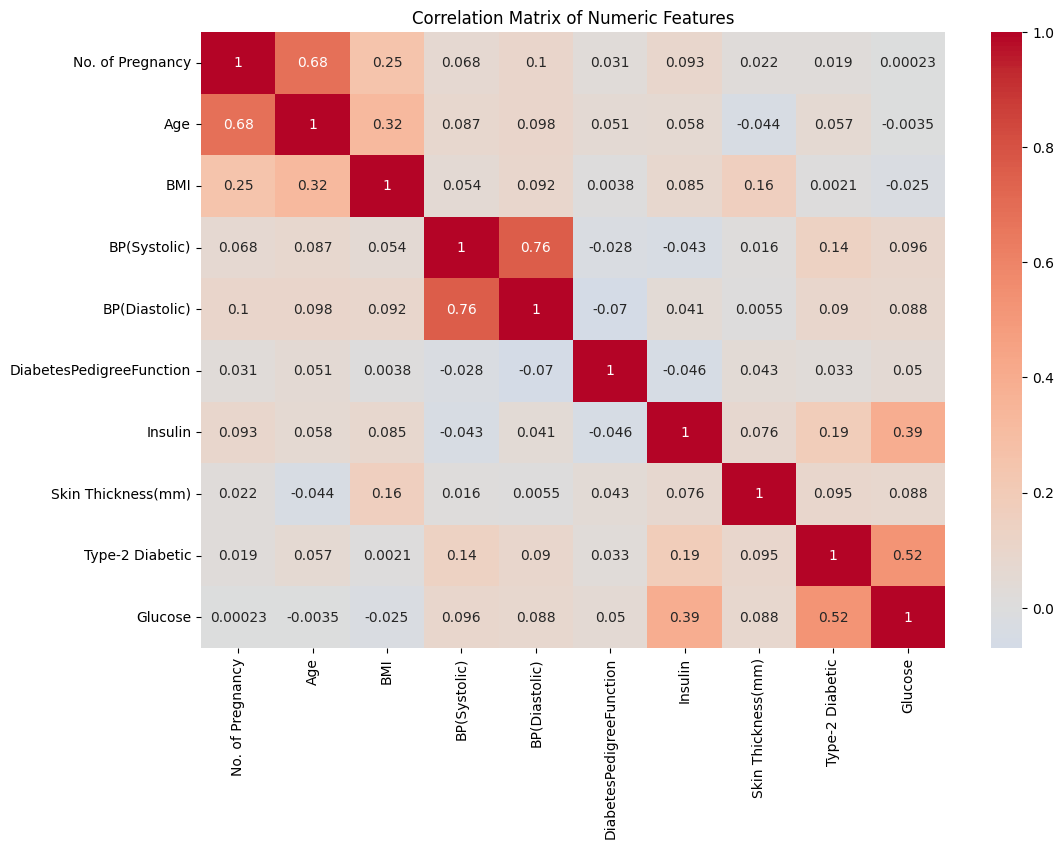

In [7]:
numeric_cols = df.select_dtypes(include = np.number).columns
plt.figure(figsize = (12, 8))
sns.heatmap(df[numeric_cols].corr(), annot = True, cmap = 'coolwarm', center = 0)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

In [8]:
# Building the feature columns
all_cols = set(df.columns) - {TARGET}
num_cols = df[list(all_cols)].select_dtypes(include = np.number).columns.drop(TARGET, errors = 'ignore').tolist()
cat_cols = df[list(all_cols)].select_dtypes(include = 'object').columns.tolist()

feature_cols = num_cols + cat_cols

print(f"Ceatures for training: {len(feature_cols)}")
print(f" - Numeric: {len(num_cols)}")
print(f" -Categorical: {len(cat_cols)}")

print('num_cols: ', num_cols)
print('cat_cols:', cat_cols)

Ceatures for training: 9
 - Numeric: 9
 -Categorical: 0
num_cols:  ['Glucose', 'Skin Thickness(mm)', 'DiabetesPedigreeFunction', 'BMI', 'BP(Diastolic)', 'Age', 'No. of Pregnancy', 'Insulin', 'BP(Systolic)']
cat_cols: []


In [9]:
featrure_cols = num_cols + cat_cols
X = df[feature_cols]
y = df[TARGET]

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Features: {len(feature_cols)} ({len(num_cols)} numeric, {len(cat_cols)} categorical)")

X shape: (1065, 9)
y shape: (1065,)
Features: 9 (9 numeric, 0 categorical)


In [10]:
# do the train test split.
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)
print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"\nClass distribution in training: {y_train.value_counts().to_dict()}")
print(f"Class distribution in test: {y_test.value_counts().to_dict()}")

Training set: (852, 9)
Test set: (213, 9)

Class distribution in training: {1: 672, 0: 180}
Class distribution in test: {1: 168, 0: 45}


In [11]:
# Build the pipeline
num_pipeline = Pipeline(steps = [
    ('imputer', SimpleImputer(strategy = 'median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline(steps= [
    ('imputer', SimpleImputer(strategy = 'most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown = 'ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

print("preprocessing pipeline created successfully.")
print(f"Total features to process: {len(num_cols) + len(cat_cols)}")

preprocessing pipeline created successfully.
Total features to process: 9


In [12]:
from  imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.ensemble import (
RandomForestClassifier,
GradientBoostingClassifier,
AdaBoostClassifier,
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report,
    roc_curve, auc, make_scorer,
)
import joblib

IMBALANCE_RATIO = 840 / 225

models = {
    # Linear model — stronger regularization + balanced classes
    "Logistic Regression": LogisticRegression(
        C=3.0,
        penalty='l1',
        solver='saga',
        max_iter=2000,
        class_weight='balanced',
        random_state=42,
    ),

    # Tree — pruned to avoid overfitting, balanced
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42,
    ),

    # Random Forest — your best params from tuning
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        max_features='sqrt',
        min_samples_leaf=7,
        min_samples_split=4,
        class_weight='balanced_subsample',
        n_jobs=-1,
        random_state=42,
    ),

    # Gradient Boosting — more estimators, lower LR, better generalization
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        min_samples_leaf=10,
        max_features='sqrt',
        random_state=42,
    ),

    # AdaBoost — shallower stumps, more of them
    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.5,
        random_state=42,
    ),

    # XGBoost — your existing good params, slight adjustments
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.03,
        scale_pos_weight=IMBALANCE_RATIO,
        subsample=0.8,
        colsample_bytree=0.7,
        min_child_weight=5,
        gamma=0.1,
        reg_alpha=0.1,
        reg_lambda=1.5,
        random_state=42,
        eval_metric='logloss',
        verbosity=0,
    ),


    "LightGBM": LGBMClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.03,
        class_weight='balanced',
        subsample=0.8,
        colsample_bytree=0.7,
        min_child_samples=20,
        reg_alpha=0.1,
        reg_lambda=1.0,
        num_leaves=40,
        random_state=42,
        verbosity=-1,
        n_jobs=-1,
    ),


    "KNN": KNeighborsClassifier(
        n_neighbors=11,
        weights='distance',
        metric='manhattan',
        n_jobs=-1,
    ),


    "Naive Bayes": GaussianNB(
        var_smoothing=1e-8,
    ),
}

print(f"Total models to evaluate: {len(models)}")
print(list(models.keys()))

Total models to evaluate: 9
['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'AdaBoost', 'XGBoost', 'LightGBM', 'KNN', 'Naive Bayes']


In [13]:
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTETomek
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": make_scorer(accuracy_score),
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}

def get_pipeline(model):
    return ImbPipeline(
        [
            ("preprocessor", preprocessor),
            ("smote", SMOTETomek(random_state=42, sampling_strategy=0.7)),
            ("model", model),
        ]
    )
def get_positive_scores(fitted_pipeline, X):
    model = fitted_pipeline.named_steps["model"]

    if hasattr(model, "predict_proba"):
        return fitted_pipeline.predict_proba(X)[:, 1]
    if hasattr(model, "decision_function"):
        return fitted_pipeline.decision_function(X)
    return None
def evaluate_test_set(fitted_pipeline, X_test, y_test):
    y_pred = fitted_pipeline.predict(X_test)
    y_score = get_positive_scores(fitted_pipeline, X_test)

    metrics = {
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(y_test, y_pred, zero_division=0),
        "Test Recall": recall_score(y_test, y_pred, zero_division=0),
        "Test F1": f1_score(y_test, y_pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, y_score)
        if y_score is not None
        else np.nan,
    }
    return y_pred, y_score, metrics

In [14]:
import time
cv_results = {}
trained_pipelines = {}
test_predictions = {}
test_scores = {}

for model_name, model in models.items():
    print(f"Cross-validating {model_name}...", end = " ")
    pipe = get_pipeline(model)
    start_time = time.time()

    cv_scores = cross_validate(
        estimator=pipe,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
    )

    cv_time = time.time() - start_time

    cv_results[model_name] = {
        "CV Accuracy Mean": cv_scores["test_accuracy"].mean(),
        "CV Accuracy Std": cv_scores["test_accuracy"].std(),
        "CV Precision Mean": cv_scores["test_precision"].mean(),
        "CV Recall Mean": cv_scores["test_recall"].mean(),
        "CV F1 Mean": cv_scores["test_f1"].mean(),
        "CV F1 Std": cv_scores["test_f1"].std(),
        "CV ROC-AUC Mean": cv_scores["test_roc_auc"].mean(),
        "CV ROC-AUC Std": cv_scores["test_roc_auc"].std(),
        "CV Time (s)": round(cv_time, 4),
    }

    fit_start = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - fit_start

    y_pred, y_score, test_metrics = evaluate_test_set(
        pipe, X_test, y_test
    )

    cv_results[model_name].update(test_metrics)
    cv_results[model_name]["Fit Time Full Train (s)"] = round(fit_time, 4)

    trained_pipelines[model_name] = pipe
    test_predictions[model_name] = y_pred
    test_scores[model_name] = y_score

    print(
        f"✅ (CV F1 mean: {cv_results[model_name]['CV F1 Mean']:.4f}, "
        f"Test F1: {cv_results[model_name]['Test F1']:.4f})"
    )

print("\n✅ All models cross-validated, fitted, and evaluated successfully!")

Cross-validating Logistic Regression... ✅ (CV F1 mean: 0.9037, Test F1: 0.9264)
Cross-validating Decision Tree... ✅ (CV F1 mean: 0.9647, Test F1: 0.9676)
Cross-validating Random Forest... ✅ (CV F1 mean: 0.9816, Test F1: 0.9766)
Cross-validating Gradient Boosting... ✅ (CV F1 mean: 0.9802, Test F1: 0.9736)
Cross-validating AdaBoost... ✅ (CV F1 mean: 0.9801, Test F1: 0.9796)
Cross-validating XGBoost... ✅ (CV F1 mean: 0.9839, Test F1: 0.9766)
Cross-validating LightGBM... 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warning

✅ (CV F1 mean: 0.9779, Test F1: 0.9674)
Cross-validating KNN... 

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


✅ (CV F1 mean: 0.9556, Test F1: 0.9524)
Cross-validating Naive Bayes... ✅ (CV F1 mean: 0.8620, Test F1: 0.8868)

✅ All models cross-validated, fitted, and evaluated successfully!


In [15]:
results_df = pd.DataFrame(cv_results).T.sort_values(
    "CV F1 Mean", ascending=False
)

print("\n" + "=" * 100)
print("MODEL RANKING BY CROSS-VALIDATED F1")
print("=" * 100)
print(results_df.round(4))
print("=" * 100)

best_model_name = results_df.index[0]
best_pipeline = trained_pipelines[best_model_name]

print(f"\n🏆 Best model from CV: {best_model_name}")
print(
    f"CV F1 Mean: {results_df.loc[best_model_name, 'CV F1 Mean']:.4f} "
    f"+/- {results_df.loc[best_model_name, 'CV F1 Std']:.4f}"
)
print(f"Test F1: {results_df.loc[best_model_name, 'Test F1']:.4f}")


MODEL RANKING BY CROSS-VALIDATED F1
                     CV Accuracy Mean  CV Accuracy Std  CV Precision Mean  \
XGBoost                        0.9742           0.0047             0.9683   
Random Forest                  0.9707           0.0053             0.9696   
Gradient Boosting              0.9683           0.0060             0.9681   
AdaBoost                       0.9683           0.0047             0.9695   
LightGBM                       0.9648           0.0052             0.9680   
Decision Tree                  0.9448           0.0109             0.9715   
KNN                            0.9308           0.0077             0.9665   
Logistic Regression            0.8592           0.0164             0.9780   
Naive Bayes                    0.8017           0.0532             0.9481   

                     CV Recall Mean  CV F1 Mean  CV F1 Std  CV ROC-AUC Mean  \
XGBoost                      1.0000      0.9839     0.0029           0.9561   
Random Forest                0.994

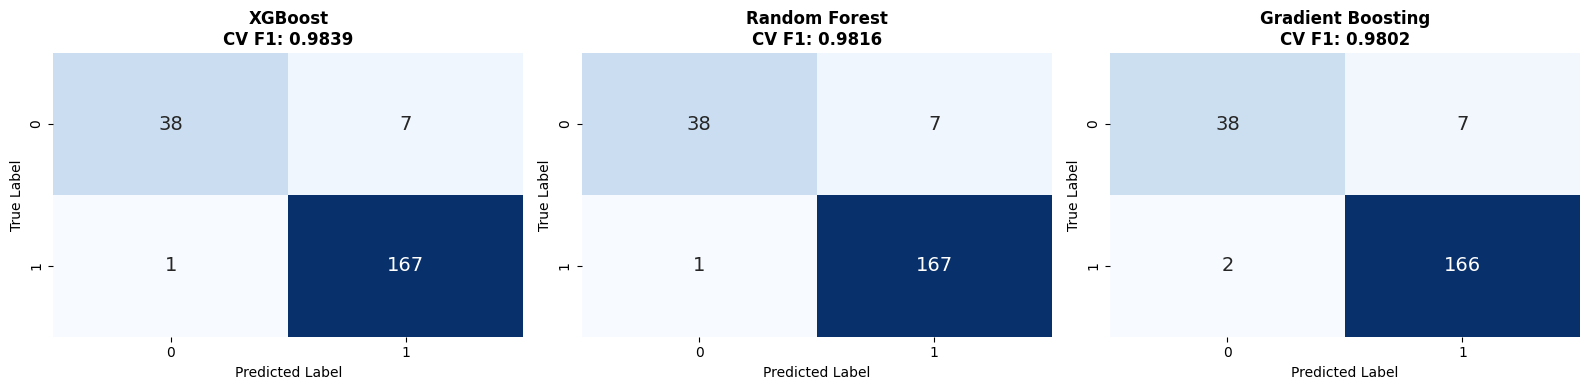

✅ Confusion matrices for top 3 CV-ranked models displayed


In [16]:
#confusion matrix for of top 3 models
# REPLACEMENT FOR:
# confusion matrix top 3 models cell

top_3_models = results_df.head(3).index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for idx, model_name in enumerate(top_3_models):
    y_pred = test_predictions[model_name]
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[idx],
        cbar=False,
        annot_kws={"size": 14},
    )

    axes[idx].set_title(
        f"{model_name}\nCV F1: {results_df.loc[model_name, 'CV F1 Mean']:.4f}",
        fontweight="bold",
    )
    axes[idx].set_ylabel("True Label")
    axes[idx].set_xlabel("Predicted Label")

plt.tight_layout()
plt.show()

print("✅ Confusion matrices for top 3 CV-ranked models displayed")

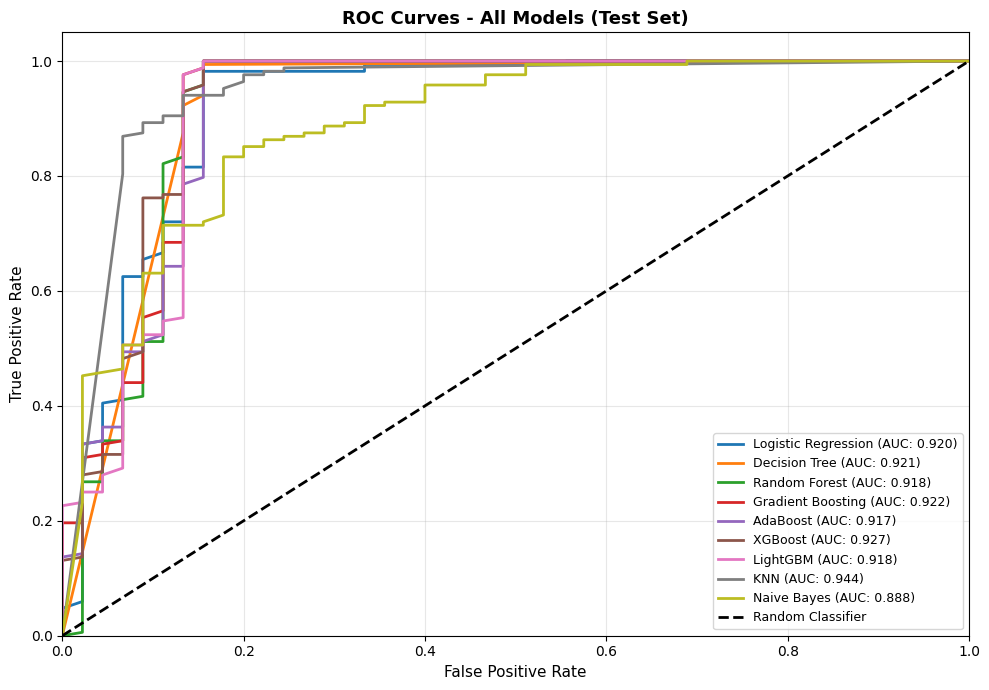

✅ ROC curves displayed


In [17]:
# ROC Curves for all models
# REPLACEMENT FOR:
# ROC curves for all models cell

plt.figure(figsize=(10, 7))

for model_name, pipe in trained_pipelines.items():
    y_score = test_scores[model_name]

    if y_score is not None:
        fpr, tpr, _ = roc_curve(y_test, y_score)
        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            lw=2,
            label=f"{model_name} (AUC: {roc_auc:.3f})",
        )

plt.plot([0, 1], [0, 1], "k--", lw=2, label="Random Classifier")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate", fontsize=11)
plt.title("ROC Curves - All Models (Test Set)", fontsize=13, fontweight="bold")
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

print("✅ ROC curves displayed")

In [18]:
best_model_name = results_df.index[0]
best_pipeline = trained_pipelines[best_model_name]
best_y_pred = test_predictions[best_model_name]

print("\n" + "=" * 60)
print(f"BEST MODEL FROM CV: {best_model_name}")
print("=" * 60)
print("\nClassification Report (Test Set):")
print(
    classification_report(
        y_test,
        best_y_pred,
        target_names=["diabetic", "not diabetic"],
        zero_division=0,
    )
)


BEST MODEL FROM CV: XGBoost

Classification Report (Test Set):
              precision    recall  f1-score   support

    diabetic       0.97      0.84      0.90        45
not diabetic       0.96      0.99      0.98       168

    accuracy                           0.96       213
   macro avg       0.97      0.92      0.94       213
weighted avg       0.96      0.96      0.96       213



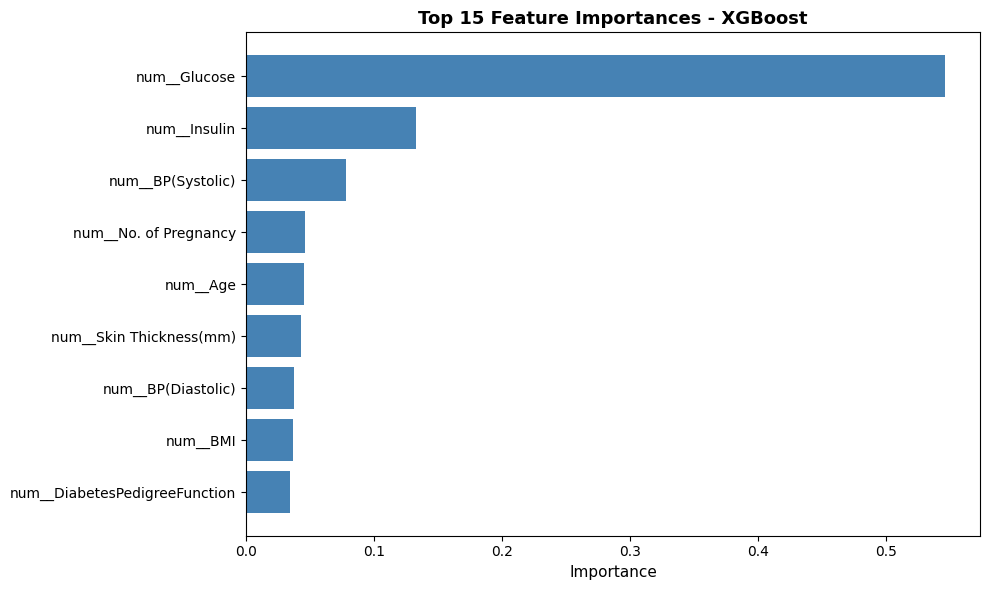


Top Feature Importances:
                         Feature  Importance
0                   num__Glucose    0.546107
7                   num__Insulin    0.132999
8              num__BP(Systolic)    0.078461
6          num__No. of Pregnancy    0.046046
5                       num__Age    0.045080
1        num__Skin Thickness(mm)    0.042988
4             num__BP(Diastolic)    0.037368
3                       num__BMI    0.036693
2  num__DiabetesPedigreeFunction    0.034258


In [19]:
best_estimator = best_pipeline.named_steps["model"]

if hasattr(best_estimator, "feature_importances_"):
    fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
    feature_names = fitted_preprocessor.get_feature_names_out()

    importance_df = pd.DataFrame(
        {
            "Feature": feature_names,
            "Importance": best_estimator.feature_importances_,
        }
    ).sort_values("Importance", ascending=False).head(15)

    plt.figure(figsize=(10, 6))
    plt.barh(
        importance_df["Feature"][::-1],
        importance_df["Importance"][::-1],
        color="steelblue",
    )
    plt.xlabel("Importance", fontsize=11)
    plt.title(
        f"Top 15 Feature Importances - {best_model_name}",
        fontsize=13,
        fontweight="bold",
    )
    plt.tight_layout()
   
    plt.show()

    print("\nTop Feature Importances:")
    print(importance_df)
else:
    print(
        f"Note: {best_model_name} does not provide built-in feature importance scores."
    )

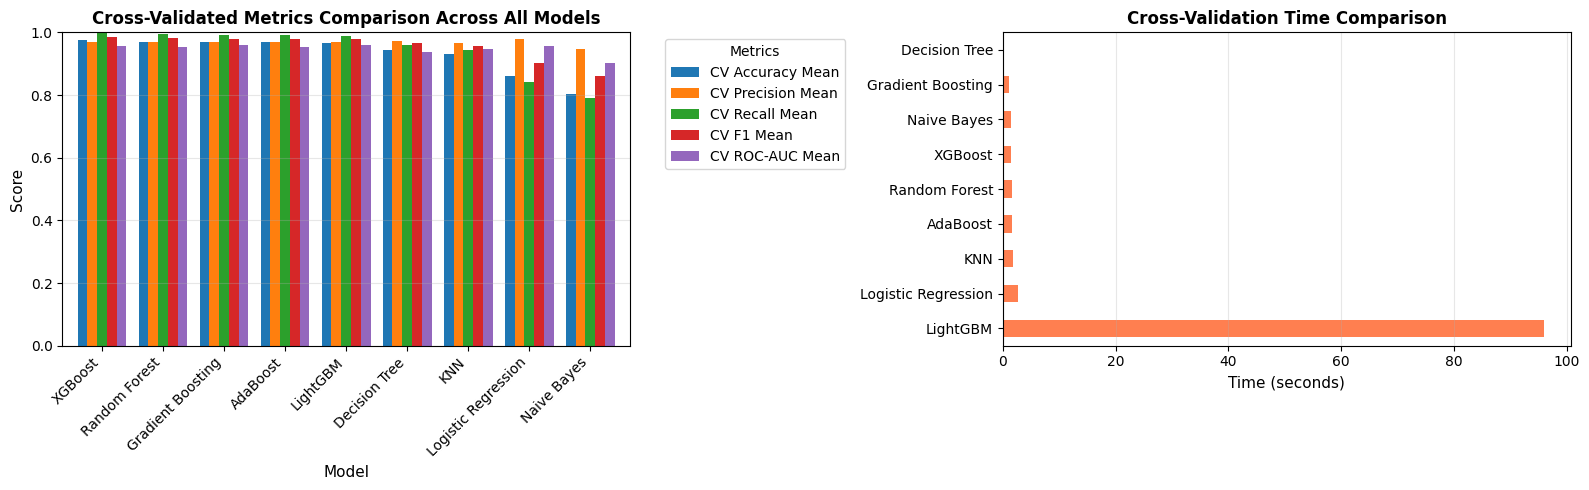

✅ CV model comparison visualizations displayed


In [20]:
# model comparison visualization cell

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

cv_metrics_to_plot = [
    "CV Accuracy Mean",
    "CV Precision Mean",
    "CV Recall Mean",
    "CV F1 Mean",
    "CV ROC-AUC Mean",
]

results_df[cv_metrics_to_plot].plot(kind="bar", ax=axes[0], width=0.8)
axes[0].set_title(
    "Cross-Validated Metrics Comparison Across All Models",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_ylabel("Score", fontsize=11)
axes[0].set_xlabel("Model", fontsize=11)
axes[0].legend(title="Metrics", bbox_to_anchor=(1.05, 1), loc="upper left")
axes[0].set_ylim([0, 1])
axes[0].grid(axis="y", alpha=0.3)
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45, ha="right")

cv_times = results_df["CV Time (s)"].sort_values(ascending=False)
cv_times.plot(kind="barh", ax=axes[1], color="coral")
axes[1].set_title(
    "Cross-Validation Time Comparison",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Time (seconds)", fontsize=11)
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.show()

print("✅ CV model comparison visualizations displayed")

In [21]:
# saving the model using joblib.
import joblib
from datetime import datetime

# Extract the model step from the pipeline (assumes it's named "model")
best_model = best_pipeline.named_steps["model"]

# Save the full pipeline (preprocessing + model) — use this for real predictions
joblib.dump(best_pipeline, f"best_pipeline_{best_model_name}.joblib")

# Save just the model, in case you need it separately
joblib.dump(best_model, f"best_model_{best_model_name}.joblib")

# Save a bundle with everything useful for later reference
model_bundle = {
    "pipeline": best_pipeline,
    "model": best_model,
    "model_name": best_model_name,
    "cv_f1_mean": results_df.loc[best_model_name, "CV F1 Mean"],
    "cv_f1_std": results_df.loc[best_model_name, "CV F1 Std"],
    "test_f1": results_df.loc[best_model_name, "Test F1"],
    "full_cv_results": results_df,
    "params": best_pipeline.get_params(),
    "trained_on": datetime.now().isoformat(),
}

joblib.dump(model_bundle, f"best_model_bundle_{best_model_name}.joblib")

print(f"\n✅ Saved pipeline, model, and bundle for '{best_model_name}'")


✅ Saved pipeline, model, and bundle for 'XGBoost'
